# Exploración y validación del dataset

## 1. Introducción

Este notebook tiene como objetivo explorar y validar el conjunto de datos utilizado en **Sentiment360**, un proyecto de análisis de opiniones escritas en español.

El dataset seleccionado, [`SetFit/amazon_reviews_multi_es`](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es), contiene reseñas de productos de Amazon asociadas a valoraciones de una a cinco estrellas. Estas valoraciones se utilizan como etiquetas para abordar un problema de clasificación supervisada.

Antes de entrenar modelos de Machine Learning y Deep Learning, es necesario conocer la estructura de los datos, verificar su calidad e identificar posibles problemas que puedan afectar al entrenamiento o a la evaluación.

### Objetivos

- Identificar la estructura, las columnas y el significado de las etiquetas.
- Analizar la distribución de las clases en las particiones oficiales.
- Detectar valores ausentes, textos vacíos, duplicados y posibles inconsistencias en las etiquetas.
- Examinar el solapamiento de textos entre entrenamiento, validación y prueba.
- Construir y verificar una evaluación complementaria sin coincidencias exactas de texto entre particiones.
- Documentar los hallazgos, las limitaciones y las decisiones metodológicas para facilitar la reproducibilidad.

### Alcance

La exploración se realiza inicialmente sobre las particiones oficiales del dataset. Cuando se requiere un filtrado para controlar el solapamiento entre particiones, los datos originales se conservan y la evaluación complementaria se genera por separado.

Los resultados de este notebook respaldan las decisiones de preparación y evaluación de datos que se utilizarán en las siguientes etapas de Sentiment360.

## Reproducibilidad

### Requisitos

La exploración se realizó con Python y las bibliotecas `datasets` y `collections`. La biblioteca `collections` forma parte de la biblioteca estándar de Python.

Se recomienda ejecutar el notebook desde el entorno virtual del proyecto, con las dependencias instaladas según los archivos de configuración del repositorio.

### Preparación y carga de los datos

El dataset se obtiene desde Hugging Face mediante `load_dataset`. No es necesario descargar ni versionar manualmente una copia del dataset dentro del repositorio.

Las particiones oficiales utilizadas son `train`, `validation` y `test`. El notebook carga las particiones necesarias, realiza las comprobaciones de calidad y construye los conjuntos de evaluación complementarios sin sobrescribir los datos originales.

### Procedimiento para reproducir el análisis

1. Clonar el repositorio e instalar sus dependencias.
2. Abrir `notebooks/01_exploracion_dataset.ipynb` en Jupyter o Google Colab.
3. Ejecutar las celdas en orden, desde la carga del dataset hasta las conclusiones.
4. Comprobar los tamaños de las particiones, las distribuciones de etiquetas y las intersecciones entre conjuntos.
5. Comparar los resultados obtenidos con los documentados en `docs/dataset.md`.

El filtrado de los conjuntos complementarios se realiza a partir de coincidencias exactas en la columna `text`. Para mantener la comparabilidad de los experimentos, debe conservarse el mismo orden de prioridad: entrenamiento, validación y prueba.

### Consideraciones

La primera ejecución puede requerir conexión a Internet para descargar el dataset desde Hugging Face. Los resultados pueden variar si cambia la versión del dataset o del código; por ello, se recomienda registrar la versión utilizada y las dependencias del entorno.

In [1]:
import sys
import pandas as pd
import datasets
import matplotlib.pyplot as plt
import sklearn
import torch

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("Datasets:", datasets.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())

Python: /home/kmontanodev/Escritorio/WorkSpace/ProyectoFinal/sentiment360/.venv/bin/python
Pandas: 3.1.0
Datasets: 5.1.0
Scikit-learn: 1.9.1
PyTorch: 2.14.1+cu130
GPU disponible: False


### Carga del dataset

In [2]:
from datasets import load_dataset

dataset = load_dataset(
    "SetFit/amazon_reviews_multi_es",
    split="train"
)

print(dataset)
print("\nColumnas:", dataset.column_names)
print("\nCantidad de registros:", len(dataset))
print("\nPrimer registro:")
print(dataset[0])

README.md:   0%|          | 0.00/310 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl: reconstructing file:   0%|          |  0.00B / 43.8MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.09M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'text', 'label', 'label_text'],
    num_rows: 200000
})

Columnas: ['id', 'text', 'label', 'label_text']

Cantidad de registros: 200000

Primer registro:
{'id': 'es_0491108', 'text': 'Nada bueno se me fue ka pantalla en menos de 8 meses y no he recibido respuesta del fabricante', 'label': 0, 'label_text': '0'}


## Distribución de clases y validación inicial de calidad

Antes de analizar posibles duplicados entre particiones, se realiza una inspección inicial del conjunto de entrenamiento para conocer la distribución de las etiquetas y comprobar la integridad básica de los registros.

### Distribución de las etiquetas

Se utiliza `Counter` para contar los registros asociados a cada valor de `label`. También se consultan los valores únicos de `label` y `label_text` para identificar las etiquetas presentes y comprobar cómo están representadas.

En este dataset, las etiquetas numéricas de `label` van de 0 a 4 y corresponden a valoraciones de una a cinco estrellas, respectivamente. La columna `label_text` contiene representaciones textuales de esos mismos valores, por lo que se inspeccionan ambas columnas para comprender el esquema real de los datos.

### Valores nulos y textos vacíos

Se comprueba si existen identificadores o textos nulos, además de reseñas que contengan únicamente espacios o estén vacías.

Estas verificaciones permiten detectar registros que podrían necesitar tratamiento antes de entrenar los modelos. Un texto ausente o vacío, por ejemplo, no proporciona contenido útil para la clasificación de opiniones.

### Identificadores y textos duplicados

Finalmente, se cuentan los identificadores repetidos y los textos repetidos dentro del conjunto de entrenamiento.

Es importante distinguir ambos casos: un identificador duplicado puede indicar un problema de integridad, mientras que un texto repetido no necesariamente representa un registro inválido. Las reseñas idénticas pueden tener etiquetas iguales o diferentes, por lo que conviene investigarlas antes de decidir si requieren algún tratamiento.

Estas comprobaciones constituyen una primera evaluación de calidad; posteriormente se analizarán con mayor detalle las etiquetas contradictorias y el solapamiento de textos entre particiones.

In [3]:
from collections import Counter

# Distribución de las etiquetas
conteo = Counter(dataset["label"])

print("Distribución de etiquetas:")
for etiqueta, cantidad in sorted(conteo.items()):
    print(f"{etiqueta}: {cantidad:,} ({cantidad / len(dataset):.2%})")

# Valores únicos de las etiquetas
print("\nValores de label:", sorted(set(dataset["label"])))
print("Valores de label_text:", sorted(set(dataset["label_text"])))

# Valores nulos o textos vacíos
nulos_id = sum(x is None for x in dataset["id"])
nulos_texto = sum(x is None for x in dataset["text"])
textos_vacios = sum(
    isinstance(x, str) and not x.strip()
    for x in dataset["text"]
)

print("\nIDs nulos:", nulos_id)
print("Textos nulos:", nulos_texto)
print("Textos vacíos:", textos_vacios)

# Duplicados
ids = dataset["id"]
textos = dataset["text"]

print("\nIDs duplicados:", len(ids) - len(set(ids)))
print("Textos duplicados:", len(textos) - len(set(textos)))

Distribución de etiquetas:
0: 40,000 (20.00%)
1: 40,000 (20.00%)
2: 40,000 (20.00%)
3: 40,000 (20.00%)
4: 40,000 (20.00%)

Valores de label: [0, 1, 2, 3, 4]
Valores de label_text: ['0', '1', '2', '3', '4']

IDs nulos: 0
Textos nulos: 0
Textos vacíos: 0

IDs duplicados: 0
Textos duplicados: 1736


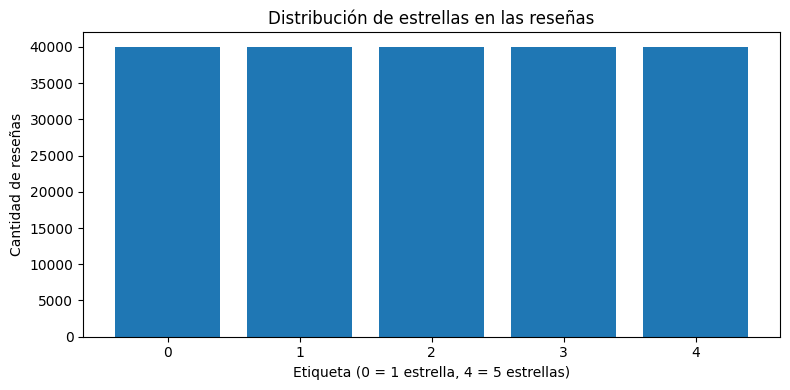

In [4]:
import matplotlib.pyplot as plt

etiquetas = sorted(conteo.keys())
cantidades = [conteo[e] for e in etiquetas]

plt.figure(figsize=(8, 4))
plt.bar(etiquetas, cantidades)
plt.title("Distribución de estrellas en las reseñas")
plt.xlabel("Etiqueta (0 = 1 estrella, 4 = 5 estrellas)")
plt.ylabel("Cantidad de reseñas")
plt.xticks(etiquetas)
plt.tight_layout()
plt.show()

### Exploracion de textos repetidos y sus etiquetas

In [5]:
import pandas as pd

df = dataset.to_pandas()

# Textos repetidos y sus etiquetas
repetidos = df[df.duplicated(subset="text", keep=False)]

print("Filas involucradas en repeticiones:", len(repetidos))
print("Textos únicos repetidos:", repetidos["text"].nunique())

# ¿Cuántos textos repetidos tienen etiquetas diferentes?
etiquetas_por_texto = repetidos.groupby("text")["label"].nunique()

conflictivos = etiquetas_por_texto[etiquetas_por_texto > 1]

print("Textos con etiquetas contradictorias:", len(conflictivos))

# Mostrar una pequeña muestra
print("\nEjemplos de textos repetidos:")
display(
    repetidos[["text", "label"]]
    .sort_values("text")
    .head(10)
)

Filas involucradas en repeticiones: 2483
Textos únicos repetidos: 747
Textos con etiquetas contradictorias: 398

Ejemplos de textos repetidos:


,text,label
168780,A la niña le ha encantado,4
164483,A la niña le ha encantado,4
98903,A mi hija le encanta,2
163908,A mi hija le encanta,4
127639,A mi hija le encanta,3
143288,A mi hija le encanta.,3
140195,A mi hija le encanta.,3
131262,A mi hija le encanto,3
193171,A mi hija le encanto,4
181284,A mi hija le ha encantado,4


In [6]:
# Analiza cuántas etiquetas tiene cada texto repetido
etiquetas_por_texto = (
    repetidos.groupby("text")["label"]
    .nunique()
)

consistentes = etiquetas_por_texto[etiquetas_por_texto == 1]
contradictorios = etiquetas_por_texto[etiquetas_por_texto > 1]

print("Grupos repetidos con etiqueta consistente:", len(consistentes))
print("Grupos repetidos con etiquetas contradictorias:", len(contradictorios))
print(
    "Porcentaje de grupos repetidos contradictorios:",
    f"{len(contradictorios) / len(etiquetas_por_texto):.2%}"
)

Grupos repetidos con etiqueta consistente: 349
Grupos repetidos con etiquetas contradictorias: 398
Porcentaje de grupos repetidos contradictorios: 53.28%


### Resultados de la validación inicial

**Distribución de clases.** El conjunto de entrenamiento contiene 200,000 registros, distribuidos equitativamente entre las cinco etiquetas: 40,000 registros por clase, equivalentes al 20 % cada una. Esto indica que no existe un desequilibrio de clases en la partición analizada.

**Representación de las etiquetas.** La columna `label` contiene los valores numéricos de 0 a 4, mientras que `label_text` contiene las cadenas `"0"` a `"4"`. La inspección confirma los valores presentes, pero el significado de las etiquetas se establece a partir de la documentación del dataset y su correspondencia con las valoraciones originales.

**Valores ausentes.** No se encontraron identificadores nulos, textos nulos ni textos vacíos. Por tanto, estas comprobaciones no identificaron registros que requieran tratamiento por ausencia de esos campos.

**Identificadores duplicados.** No se encontraron identificadores duplicados, lo que indica que la columna `id` no presenta repeticiones según la comprobación realizada.

**Textos duplicados.** Se detectaron 1,736 repeticiones adicionales de texto al comparar el número total de registros con el número de textos únicos. Este resultado no equivale al número de textos únicos que se repiten ni al número de grupos con etiquetas contradictorias; esas cantidades requieren un análisis específico posterior.

### Decisiones iniciales

Se conserva el conjunto de entrenamiento original sin eliminar registros automáticamente. Los textos repetidos se investigan por separado para determinar si comparten etiquetas y evaluar su posible impacto en el entrenamiento y la evaluación de los modelos.

### Sopalamiento entre Particiones

**Objetivo**
Se Analizar las coincidencias entre train, validation y test, y explicar el riesgo de fuga de datos.

In [7]:
from datasets import get_dataset_split_names, load_dataset

nombre_dataset = "SetFit/amazon_reviews_multi_es"

particiones = get_dataset_split_names(nombre_dataset)
print("Particiones disponibles:", particiones)

Repo card metadata block was not found. Setting CardData to empty.


Particiones disponibles: ['train', 'validation', 'test']


In [8]:
for particion in particiones:
    datos = load_dataset(nombre_dataset, split=particion)

    print(
        f"{particion}: "
        f"{len(datos):,} registros"
    )

Repo card metadata block was not found. Setting CardData to empty.
Repo card metadata block was not found. Setting CardData to empty.


train: 200,000 registros


Repo card metadata block was not found. Setting CardData to empty.


validation: 5,000 registros
test: 5,000 registros


Se analizaran las 3 particiones encontradas
- train: 200,000 registros
- validation: 5,000 registros
- test: 5,000 registros

In [9]:
from collections import Counter
from datasets import load_dataset

nombre_dataset = "SetFit/amazon_reviews_multi_es"

for particion in ["train", "validation", "test"]:
    datos = load_dataset(nombre_dataset, split=particion)
    conteo = Counter(datos["label"])

    print(f"\n--- {particion.upper()} ---")

    for etiqueta in sorted(conteo):
        cantidad = conteo[etiqueta]
        porcentaje = cantidad / len(datos) * 100

        print(
            f"Etiqueta {etiqueta}: "
            f"{cantidad:,} ({porcentaje:.2f} %)"
        )

Repo card metadata block was not found. Setting CardData to empty.



--- TRAIN ---
Etiqueta 0: 40,000 (20.00 %)
Etiqueta 1: 40,000 (20.00 %)
Etiqueta 2: 40,000 (20.00 %)
Etiqueta 3: 40,000 (20.00 %)
Etiqueta 4: 40,000 (20.00 %)


Repo card metadata block was not found. Setting CardData to empty.



--- VALIDATION ---
Etiqueta 0: 1,000 (20.00 %)
Etiqueta 1: 1,000 (20.00 %)
Etiqueta 2: 1,000 (20.00 %)
Etiqueta 3: 1,000 (20.00 %)
Etiqueta 4: 1,000 (20.00 %)


Repo card metadata block was not found. Setting CardData to empty.



--- TEST ---
Etiqueta 0: 1,000 (20.00 %)
Etiqueta 1: 1,000 (20.00 %)
Etiqueta 2: 1,000 (20.00 %)
Etiqueta 3: 1,000 (20.00 %)
Etiqueta 4: 1,000 (20.00 %)


In [10]:
from datasets import load_dataset

nombre_dataset = "SetFit/amazon_reviews_multi_es"

train = load_dataset(nombre_dataset, split="train")
validation = load_dataset(nombre_dataset, split="validation")
test = load_dataset(nombre_dataset, split="test")

textos_train = set(train["text"])
textos_validation = set(validation["text"])
textos_test = set(test["text"])

print("Train ∩ Validation:", len(textos_train & textos_validation))
print("Train ∩ Test:", len(textos_train & textos_test))
print("Validation ∩ Test:", len(textos_validation & textos_test))

Repo card metadata block was not found. Setting CardData to empty.
Repo card metadata block was not found. Setting CardData to empty.
Repo card metadata block was not found. Setting CardData to empty.


Train ∩ Validation: 66
Train ∩ Test: 57
Validation ∩ Test: 9


In [11]:
def etiquetas_por_texto(dataset):
    resultado = {}

    for texto, etiqueta in zip(dataset["text"], dataset["label"]):
        resultado.setdefault(texto, set()).add(etiqueta)

    return resultado


particiones = {
    "train": train,
    "validation": validation,
    "test": test,
}

mapas = {
    nombre: etiquetas_por_texto(datos)
    for nombre, datos in particiones.items()
}

pares = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]

for nombre_a, nombre_b in pares:
    mapa_a = mapas[nombre_a]
    mapa_b = mapas[nombre_b]

    comunes = mapa_a.keys() & mapa_b.keys()

    contradictorios = sum(
        len(mapa_a[texto] | mapa_b[texto]) > 1
        for texto in comunes
    )

    print(f"\n{nombre_a} ∩ {nombre_b}")
    print("Textos compartidos:", len(comunes))
    print("Con etiquetas contradictorias:", contradictorios)


train ∩ validation
Textos compartidos: 66
Con etiquetas contradictorias: 41

train ∩ test
Textos compartidos: 57
Con etiquetas contradictorias: 40

validation ∩ test
Textos compartidos: 9
Con etiquetas contradictorias: 3


In [12]:
# Conjuntos de textos únicos de cada partición
textos_train = set(train["text"])
textos_validation = set(validation["text"])
textos_test = set(test["text"])

# Intersección de las tres particiones
en_las_tres = (
    textos_train
    & textos_validation
    & textos_test
)

# Textos compartidos por al menos dos particiones
en_varias = (
    (textos_train & textos_validation)
    | (textos_train & textos_test)
    | (textos_validation & textos_test)
)

# Textos exclusivos de cada partición, respecto a las otras dos
solo_train = textos_train - (textos_validation | textos_test)
solo_validation = textos_validation - (textos_train | textos_test)
solo_test = textos_test - (textos_train | textos_validation)

print("Textos presentes en las tres particiones:", len(en_las_tres))
print("Textos únicos compartidos por al menos dos:", len(en_varias))

print("\nTextos exclusivos de cada partición:")
print("Train:", len(solo_train))
print("Validation:", len(solo_validation))
print("Test:", len(solo_test))

Textos presentes en las tres particiones: 6
Textos únicos compartidos por al menos dos: 120

Textos exclusivos de cada partición:
Train: 198147
Validation: 4926
Test: 4934


## Construcción de los conjuntos de evaluación complementarios

### ¿Por qué necesitamos este procedimiento?

Durante el análisis de las particiones originales se detectaron textos idénticos compartidos entre `train`, `validation` y `test`. Este solapamiento puede introducir **fuga de datos (*data leakage*)**, ya que un modelo podría encontrar durante la evaluación textos que también estuvieron presentes durante su entrenamiento o durante otra partición utilizada para el desarrollo.

Para estudiar el rendimiento de los modelos bajo una evaluación sin coincidencias exactas de texto entre particiones, se construyen conjuntos complementarios de validación y prueba. Los conjuntos oficiales se conservan sin modificaciones.

### Estrategia aplicada

Se establece el siguiente orden de prioridad:

1. **Train:** se conserva íntegramente, ya que constituye la base para el entrenamiento de los modelos.
2. **Validation complementario:** se excluyen las filas cuyo texto aparece en `train`.
3. **Test complementario:** se excluyen las filas cuyo texto aparece en `train` o en el conjunto original de `validation`.

Esta estrategia prioriza el entrenamiento, después la validación y finalmente la prueba. Se utiliza la coincidencia exacta de la columna `text` para identificar los registros que deben excluirse.

### ¿Por qué se utilizan conjuntos (`set`)?

Los conjuntos permiten representar textos únicos y realizar operaciones de pertenencia e intersección de forma eficiente. En particular, el operador `|` permite unir los textos de dos particiones, mientras que `&` permite identificar los elementos compartidos.

El filtrado se realiza por coincidencia exacta del texto: no elimina paráfrasis, variantes de puntuación ni otros posibles duplicados aproximados.

**Importante:** los datos originales no se sobrescriben. `validation_limpio` y `test_limpio` son nuevas particiones destinadas a una evaluación complementaria. Esta estrategia no elimina duplicados internos de `train` ni resuelve las etiquetas contradictorias detectadas durante la exploración.

In [13]:
# Conjuntos de textos originales
textos_train = set(train["text"])
textos_validation = set(validation["text"])

# Mantener train intacto.
# Excluir de validation los textos que aparecen en train.
validation_limpio = validation.filter(
    lambda fila: fila["text"] not in textos_train
)

# Excluir de test los textos que aparecen en train o validation originales.
textos_anteriores = textos_train | textos_validation

test_limpio = test.filter(
    lambda fila: fila["text"] not in textos_anteriores
)

print("=== Tamaños originales ===")
print("Train:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

print("\n=== Evaluación complementaria ===")
print("Train:", len(train))
print("Validation:", len(validation_limpio))
print("Test:", len(test_limpio))

print("\n=== Filas excluidas de la evaluación ===")
print("Validation:", len(validation) - len(validation_limpio))
print("Test:", len(test) - len(test_limpio))

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

=== Tamaños originales ===
Train: 200000
Validation: 5000
Test: 5000

=== Evaluación complementaria ===
Train: 200000
Validation: 4929
Test: 4934

=== Filas excluidas de la evaluación ===
Validation: 71
Test: 66


## 7. Verificación de coincidencias entre particiones

Después de construir los conjuntos complementarios, es necesario comprobar que el procedimiento ha cumplido su objetivo.

Para ello, se convierten las columnas de texto en conjuntos y se calculan las intersecciones entre cada par de particiones:

- `train` y `validation_limpio`.
- `train` y `test_limpio`.
- `validation_limpio` y `test_limpio`.

La operación de intersección (`&`) devuelve los textos presentes en ambos conjuntos. Al aplicar `len()` al resultado se obtiene el número de textos únicos compartidos.

El resultado esperado es **cero coincidencias exactas en las tres intersecciones**. Si alguna intersección fuera distinta de cero, sería necesario revisar el procedimiento antes de utilizar estas particiones para evaluar los modelos.

Esta comprobación valida la ausencia de coincidencias textuales exactas entre particiones; no garantiza que no existan textos semánticamente similares ni elimina las inconsistencias internas del conjunto de entrenamiento.

In [14]:
textos_train = set(train["text"])
textos_validation_limpio = set(validation_limpio["text"])
textos_test_limpio = set(test_limpio["text"])

print(
    "Train ∩ Validation:",
    len(textos_train & textos_validation_limpio)
)
print(
    "Train ∩ Test:",
    len(textos_train & textos_test_limpio)
)
print(
    "Validation ∩ Test:",
    len(textos_validation_limpio & textos_test_limpio)
)

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


## Análisis de los conjuntos complementarios

### Tamaño de las particiones

El filtrado puede reducir el número de registros disponibles para validación y prueba. Por ello, se comparan los tamaños originales con los tamaños obtenidos después del procedimiento y se contabilizan las filas excluidas.

Este análisis permite cuantificar el impacto del filtrado y verificar que se conserva una cantidad suficiente de datos para evaluar los modelos.

### Distribución de las etiquetas

Además de comprobar el tamaño de las particiones, se analiza la distribución de las cinco clases en `validation_limpio` y `test_limpio`.

El dataset utiliza etiquetas ordinales de 0 a 4, correspondientes a valoraciones de una a cinco estrellas, respectivamente. Se calcula la cantidad y el porcentaje de registros de cada clase para determinar si el filtrado ha alterado significativamente el equilibrio observado en las particiones originales.

Una distribución equilibrada facilita la interpretación de las métricas de evaluación, aunque por sí sola no garantiza que todas las clases sean igualmente fáciles de predecir.

Los resultados se interpretan junto con los tamaños finales y la verificación del solapamiento, antes de utilizar estos conjuntos en los experimentos de Machine Learning y Deep Learning.

In [15]:
from collections import Counter

for nombre, datos in [
    ("Validation complementario", validation_limpio),
    ("Test complementario", test_limpio),
]:
    conteo = Counter(datos["label"])
    total = len(datos)

    print(f"\n=== {nombre} ===")
    print(f"Total de registros: {total:,}")

    for etiqueta in range(5):
        cantidad = conteo.get(etiqueta, 0)
        porcentaje = cantidad / total * 100 if total else 0

        print(
            f"Etiqueta {etiqueta} "
            f"({etiqueta + 1} estrella(s)): "
            f"{cantidad:,} ({porcentaje:.2f}%)"
        )


=== Validation complementario ===
Total de registros: 4,929
Etiqueta 0 (1 estrella(s)): 987 (20.02%)
Etiqueta 1 (2 estrella(s)): 996 (20.21%)
Etiqueta 2 (3 estrella(s)): 987 (20.02%)
Etiqueta 3 (4 estrella(s)): 979 (19.86%)
Etiqueta 4 (5 estrella(s)): 980 (19.88%)

=== Test complementario ===
Total de registros: 4,934
Etiqueta 0 (1 estrella(s)): 992 (20.11%)
Etiqueta 1 (2 estrella(s)): 991 (20.09%)
Etiqueta 2 (3 estrella(s)): 993 (20.13%)
Etiqueta 3 (4 estrella(s)): 984 (19.94%)
Etiqueta 4 (5 estrella(s)): 974 (19.74%)


### Conclusiones de la evaluación complementaria

La construcción de los conjuntos complementarios permitió conservar los 200,000 registros de entrenamiento y obtener 4,929 registros de validación y 4,934 de prueba. Se excluyeron 71 filas de validación y 66 de prueba, para un total de 137 filas excluidas de los conjuntos de evaluación originales.

La verificación de las intersecciones confirmó que no existen coincidencias exactas de texto entre las tres particiones complementarias.

La distribución de las etiquetas se mantiene equilibrada: cada clase representa aproximadamente el 20 % de los registros tanto en validación como en prueba. Por tanto, el filtrado no produjo un desequilibrio significativo entre las cinco clases.

Estos resultados respaldan el uso de los conjuntos complementarios para evaluar los modelos sin solapamiento textual exacto entre particiones. No obstante, se mantienen dos limitaciones relevantes: pueden existir textos similares que no sean idénticos y el conjunto de entrenamiento conserva los duplicados internos y las posibles contradicciones de etiquetas identificadas previamente.

En consecuencia, los conjuntos oficiales se mantienen como referencia original y las particiones complementarias se utilizarán como una evaluación adicional, aplicando el mismo procedimiento a todos los modelos para asegurar una comparación consistente.